# Main: asylum application forecasts, full workflow

**Purpose:** Run preprocessing, estimation, evaluation, the final test and the ranges in order.  
**Input:** `../data/raw/eurostat_asylum_ch_monthly.csv` and `../data/raw/frontex_detections_by_route_monthly.csv`.  
**Output:** CSV files in `../data/processed/`, tables in `../output/tables/` and figures in `../output/figures/`.

Run with `code/` as the working directory; see the README. The whole workflow takes about three minutes.

In [1]:
%pip install nbformat

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np

np.random.seed(42)

Number of rows: 225
First month: 2008-01-01 00:00:00
Last month:  2026-09-01 00:00:00

Missing values per column:
applicants_total           0
applicants_first_time      0
applicants_subsequent    156
dtype: int64
Expected number of months: 225
Number of months in the data: 225
No gaps: True
Smallest monthly value of applicants_total: 330
period
backtest    141
training     60
test         24
Name: count, dtype: int64
Months used for exploration: 201
From 2008-01-01 00:00:00 to 2024-09-01 00:00:00


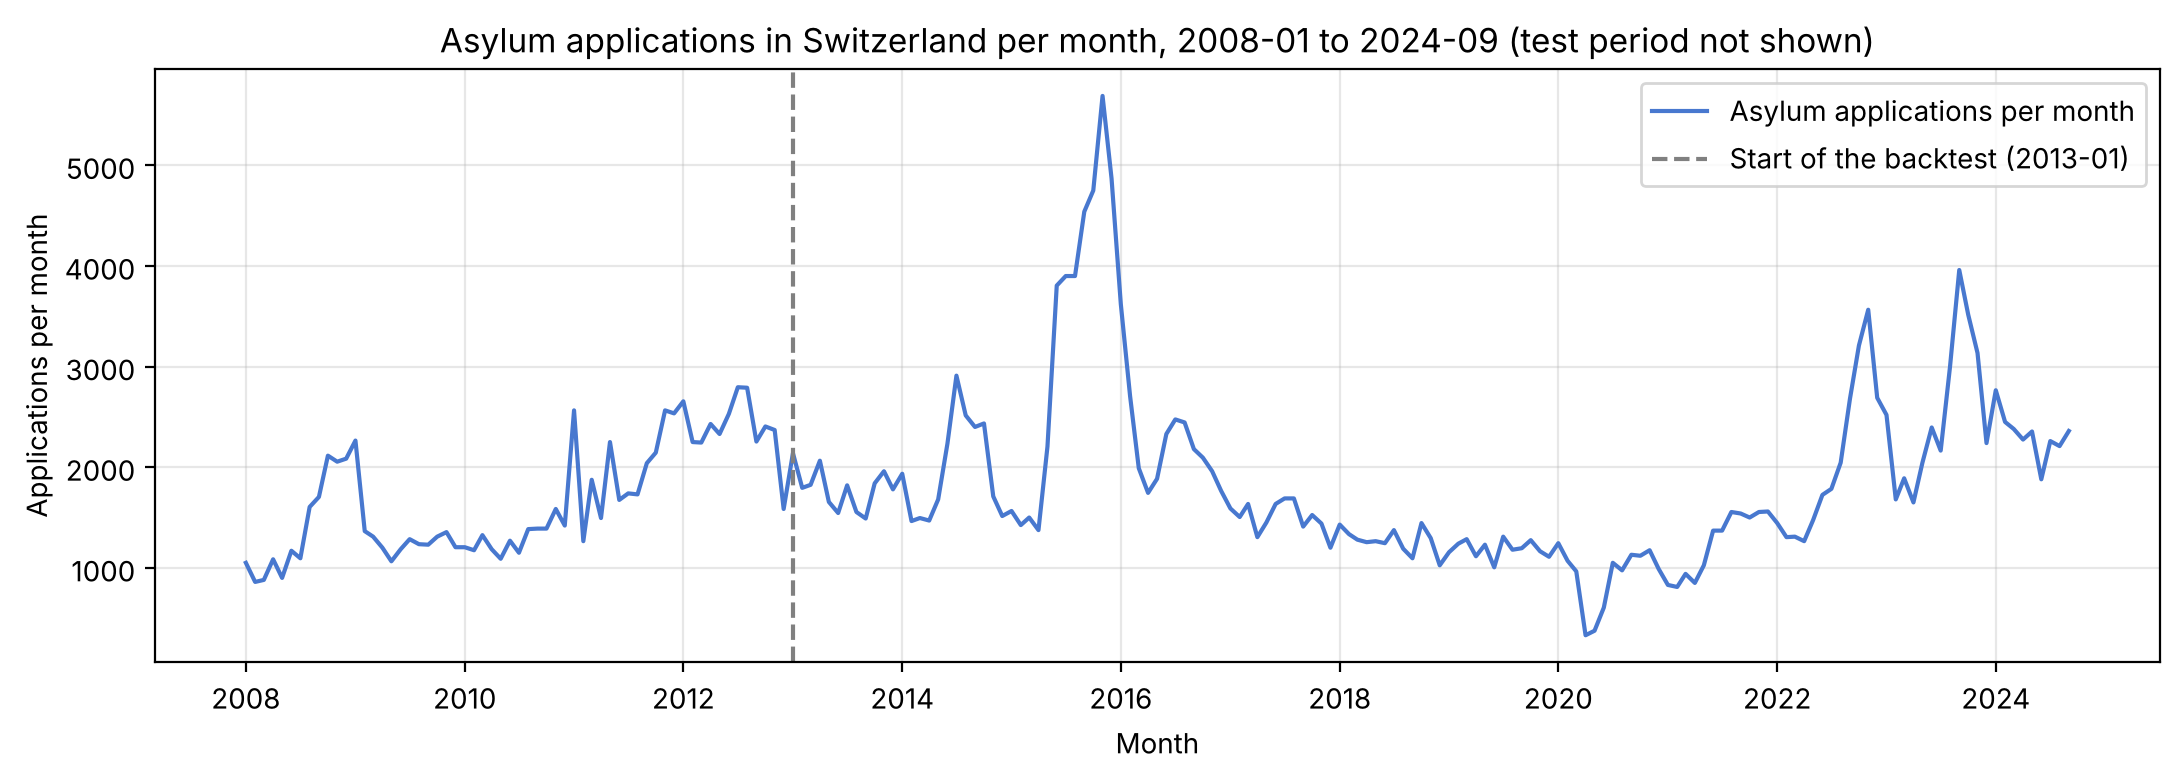

Highest months:
month
2015-11-01    5690
2015-12-01    4870
2015-10-01    4750
Name: applicants_total, dtype: int64

Lowest months:
month
2020-04-01    330
2020-05-01    375
2020-06-01    605
Name: applicants_total, dtype: int64


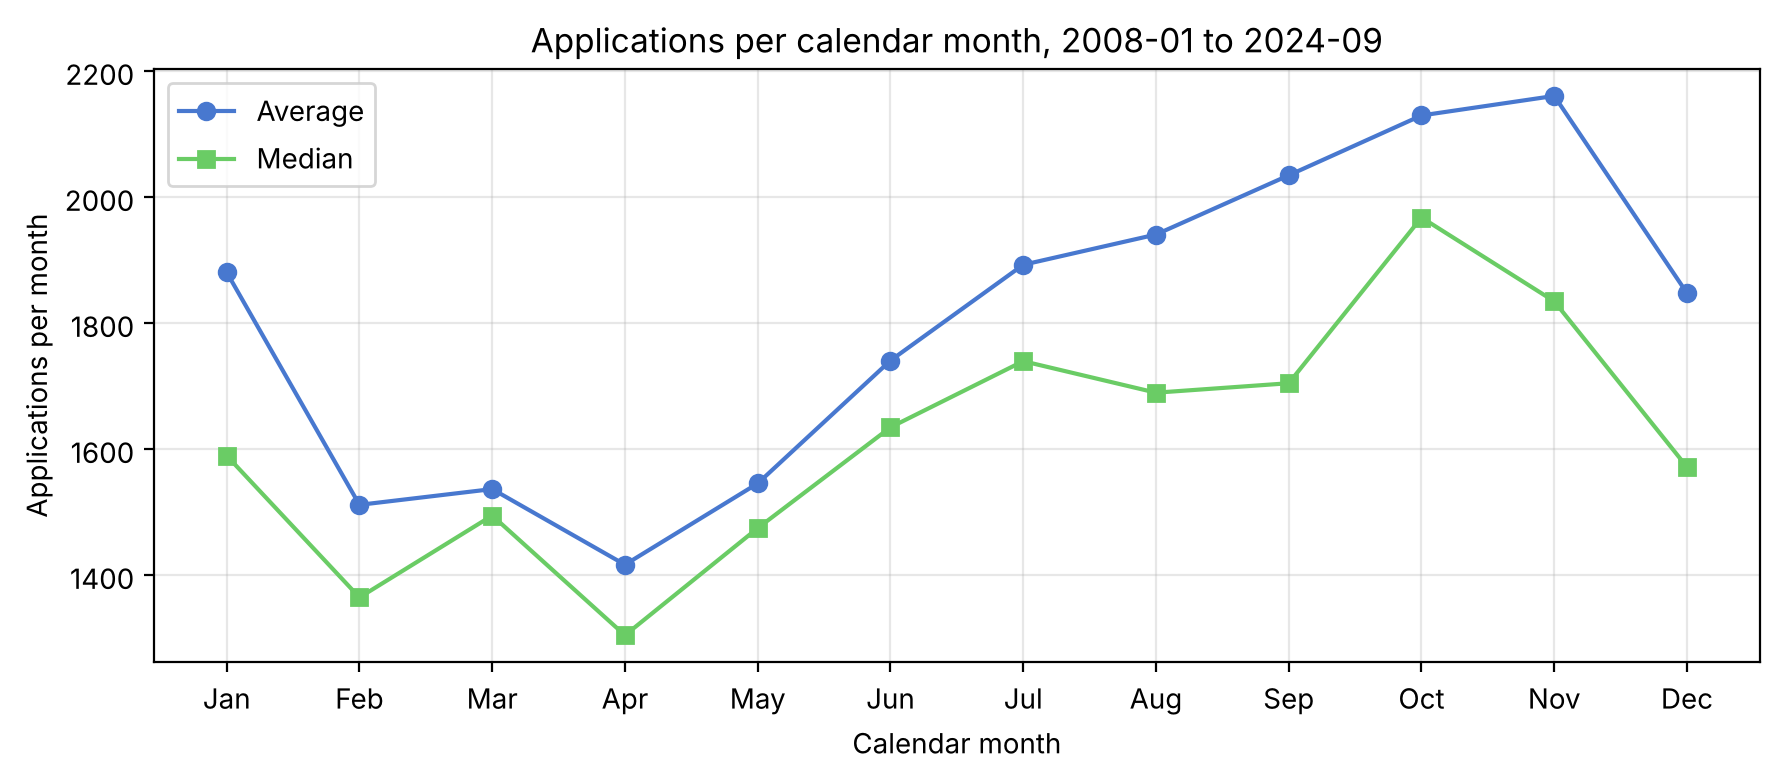

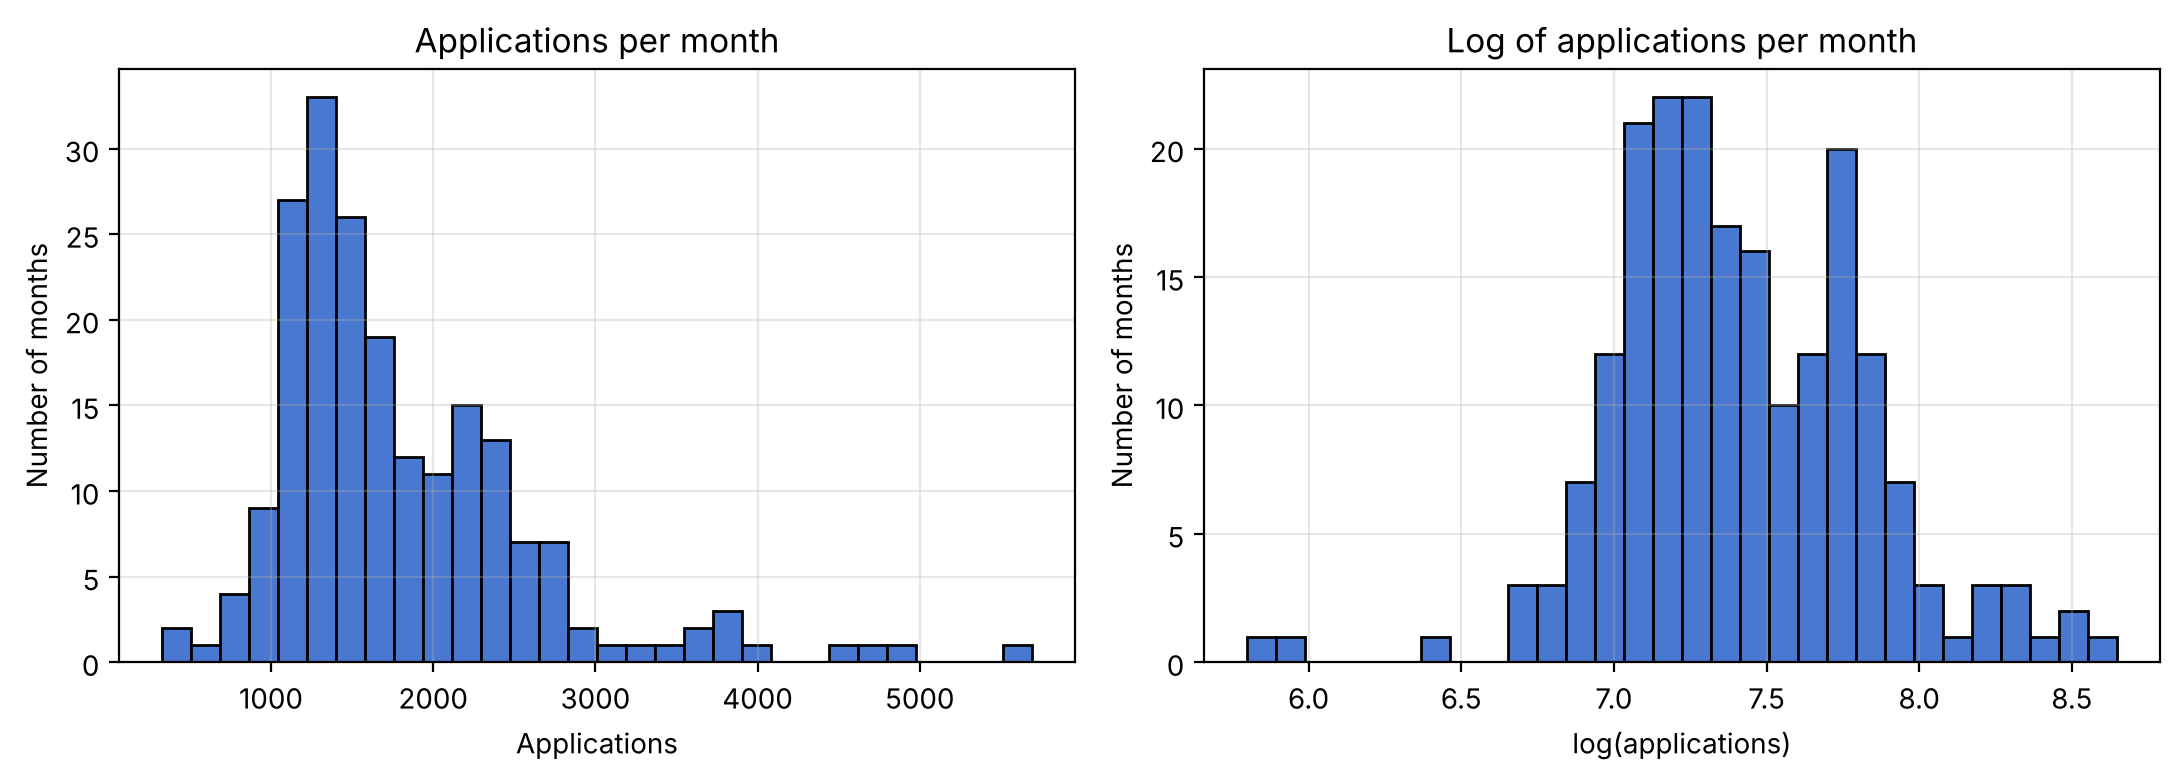

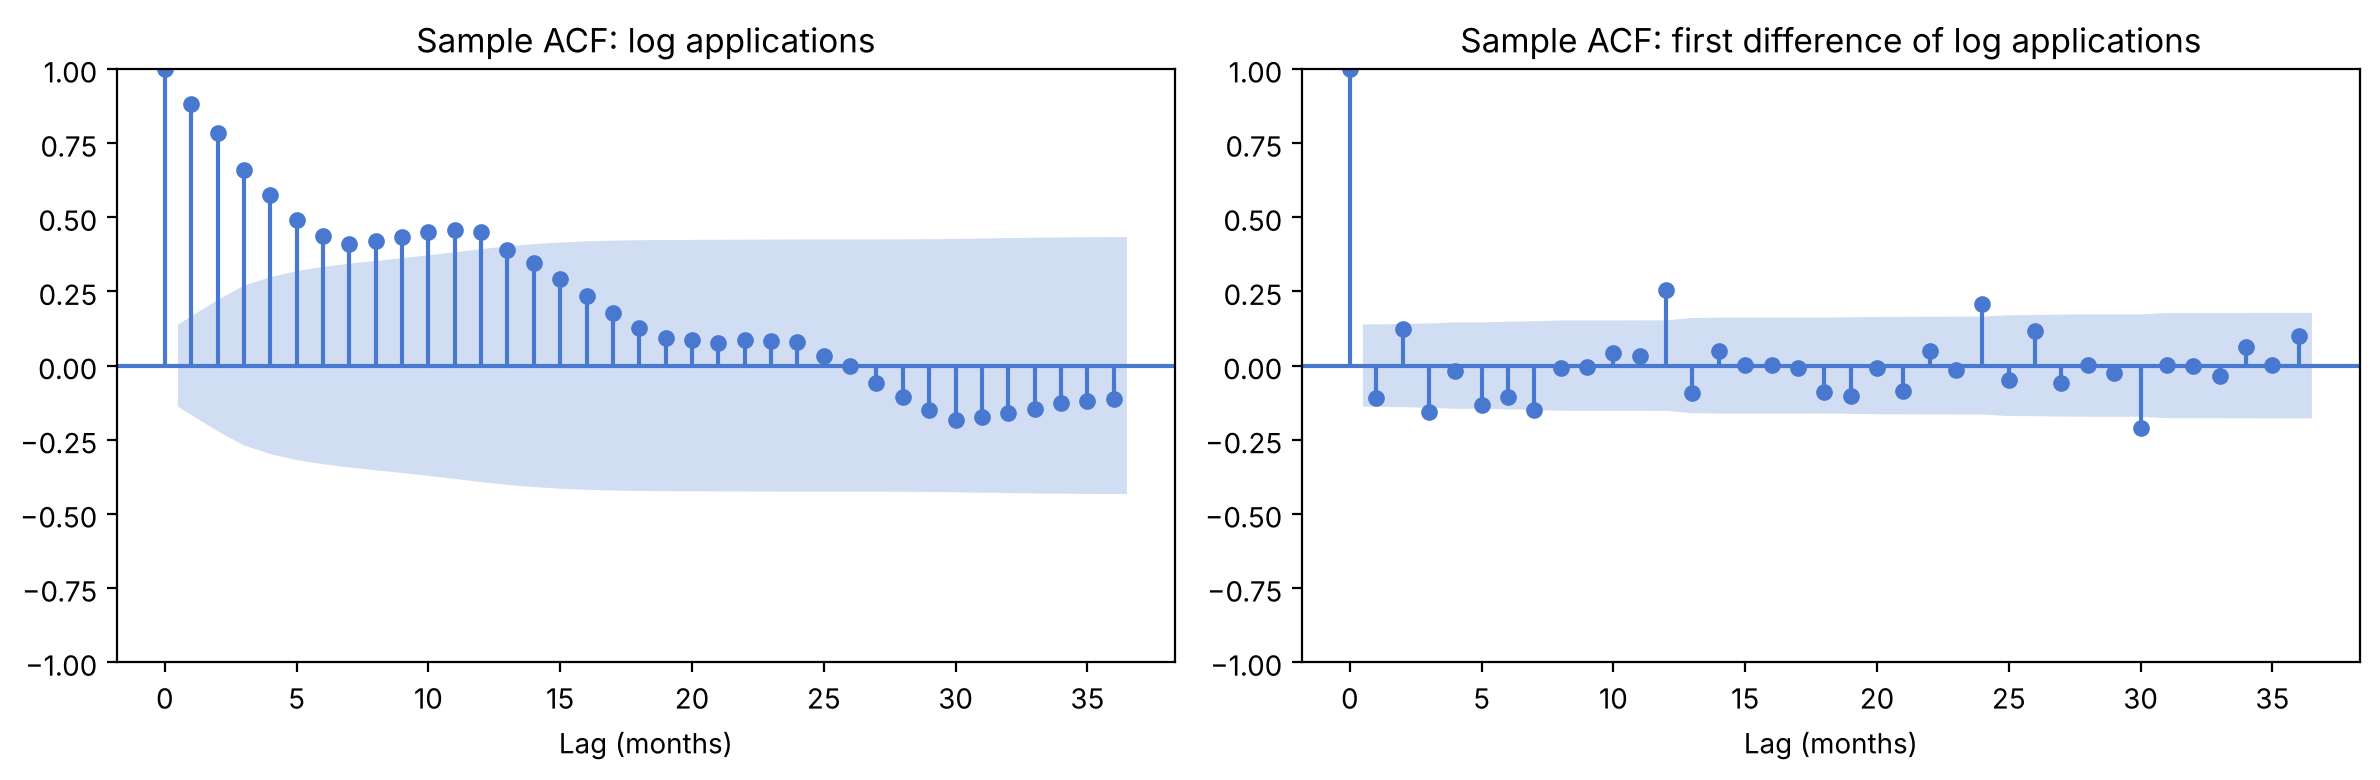

log applications                         ADF statistic  -2.023   p-value 0.2766   -> do not reject the unit root at 5%
first difference of log applications     ADF statistic  -8.047   p-value 0.0000   -> reject the unit root at 5%
Saved 225 months and the columns ['month', 'applicants_total', 'log_applicants', 'period']


In [3]:
%run 01_preprocess.ipynb

Number of months: 213
First month: 2009-01-01 00:00:00
Last month:  2026-09-01 00:00:00
Expected number of months: 213 | in the data: 213
Missing values: 0

Number of months with zero detections, per route:
eastern_mediterranean                      0
central_mediterranean                      1
western_mediterranean                      0
western_african                           29
western_balkan                             0
eastern_borders                            0
circular_route_from_albania_to_greece      0
black_sea                                182
other                                    179
dtype: int64
Smallest monthly value of the sum: 952
Share of all detections on all routes (2009-01 to 2026-09): 0.871
Last month in the Frontex file: 2026-09-01 00:00:00 (file dated 4 November 2026)
Months with both series, before the test period: 189
From 2009-01-01 00:00:00 to 2024-09-01 00:00:00


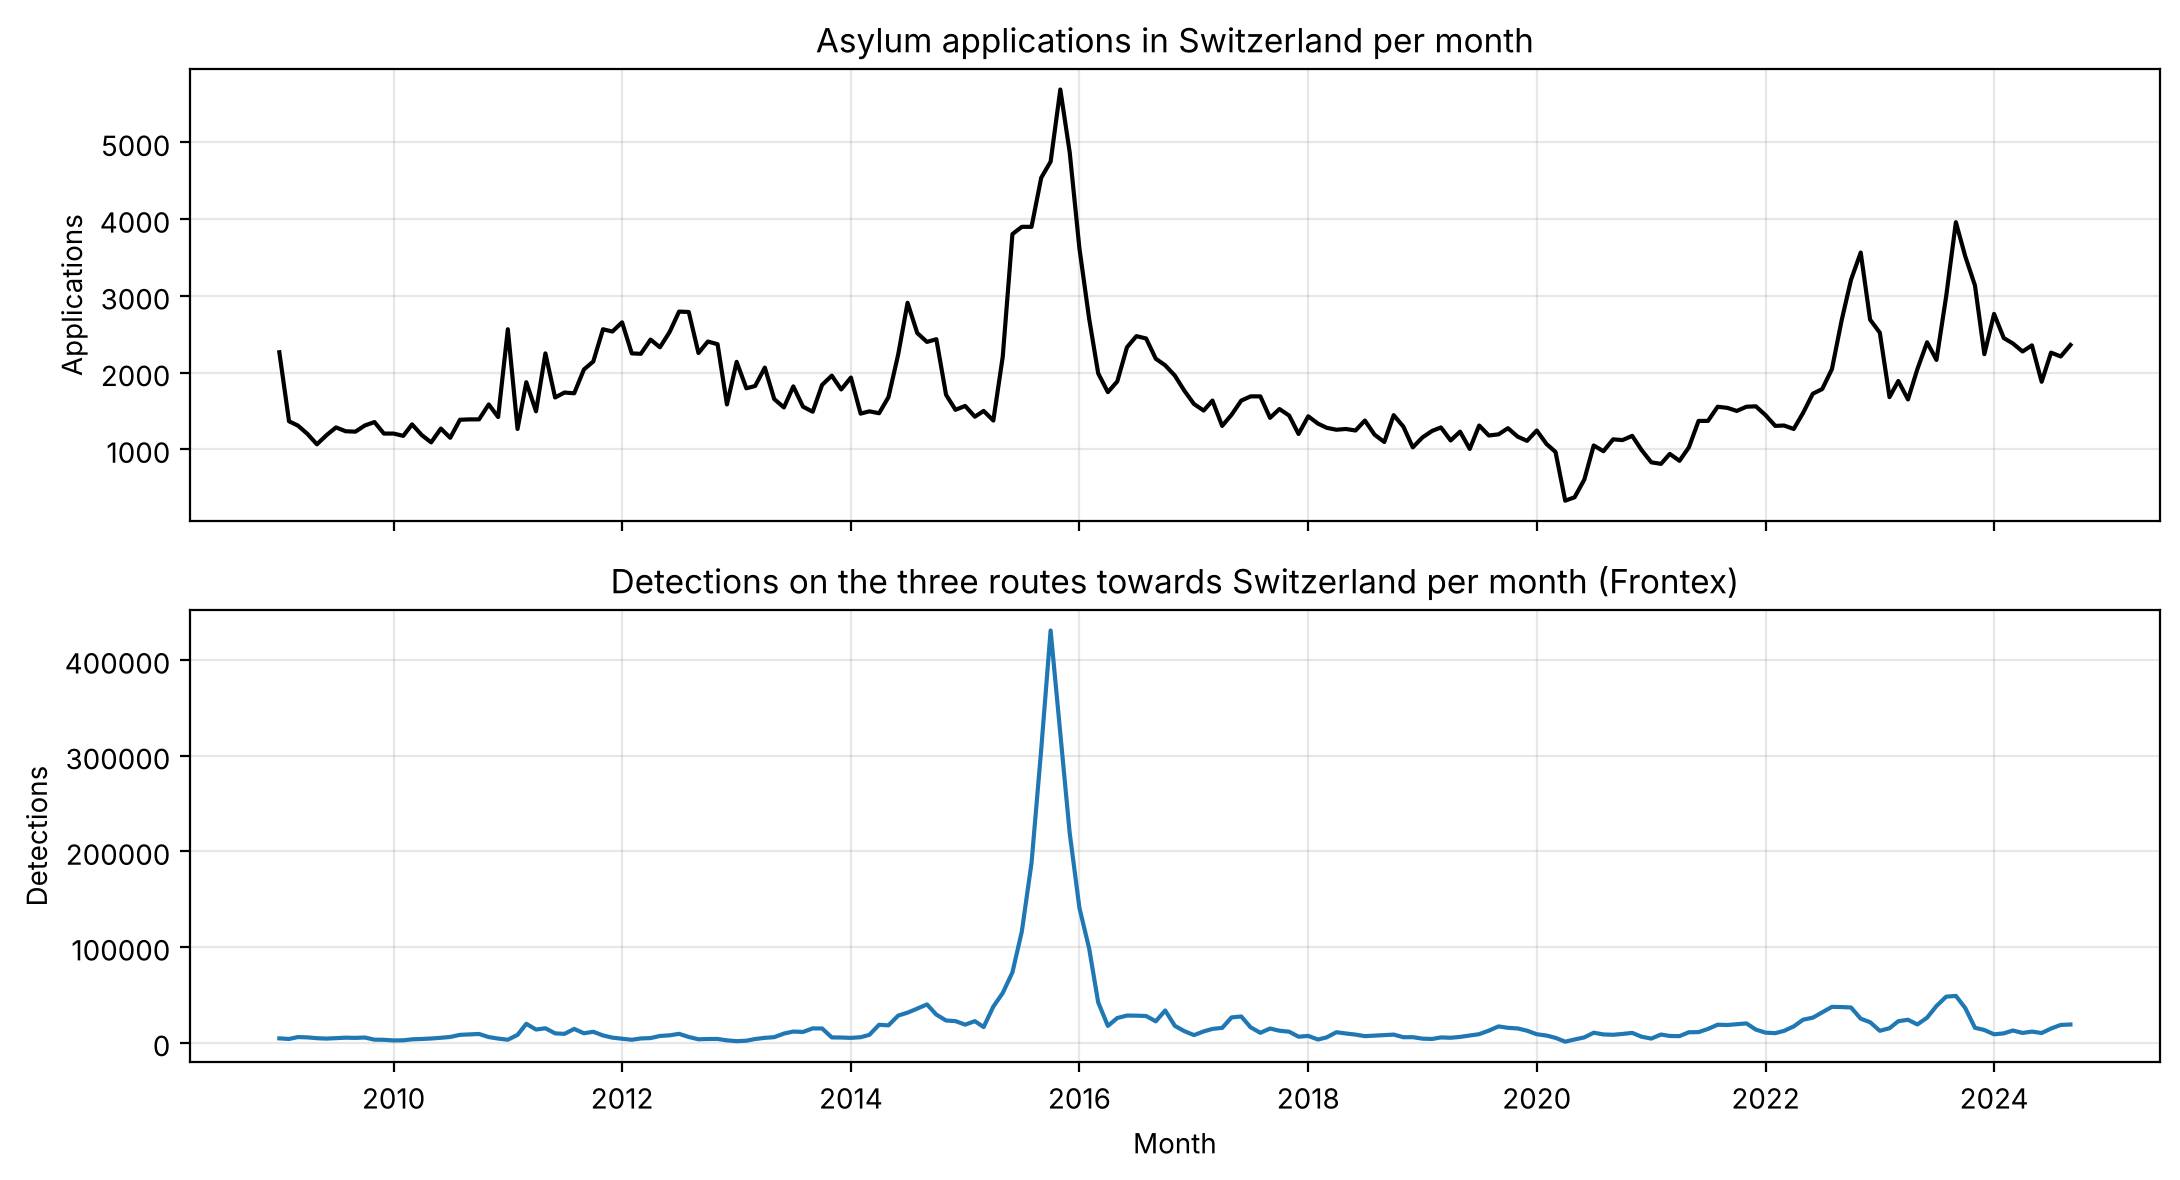

month
2015-10-01    430879
2015-11-01    322656
2015-09-01    306699
Name: routes_to_switzerland, dtype: int64
Saved 213 months and the columns ['month', 'central_mediterranean', 'eastern_mediterranean', 'western_balkan', 'routes_to_switzerland', 'log_routes']


In [4]:
%run 01b_preprocess_indicators.ipynb

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Position of the first origin: 59 -> 2012-12-01 00:00:00
Position of the last backtest month: 200 -> 2024-09-01 00:00:00
Number of origins: 141
Training months: 60 | from 2008-01-01 00:00:00 to 2012-12-01 00:00:00


Number of stored forecasts: 2520
Number of forecasts per model and horizon:
model                   h
12-month average        1    141
                        2    140
                        3    139
ARIMA(1,1,0)            1    141
                        2    140
                        3    139
Random walk             1    141
                        2    140
                        3    139
SARIMA(0,1,1)(0,1,1)12  1    141
                        2    140
                        3    139
SARIMA(1,1,0)(1,0,0)12  1    141
                        2    140
                        3    139
Seasonal naive          1    141
                        2    140
                        3    139
dtype: int64
Last forecast month: 2024-09-01 00:00:00
All forecast months in the backtest (before 2024-10): True
All forecast months after their origin: True
Missing or infinite forecasts: 0


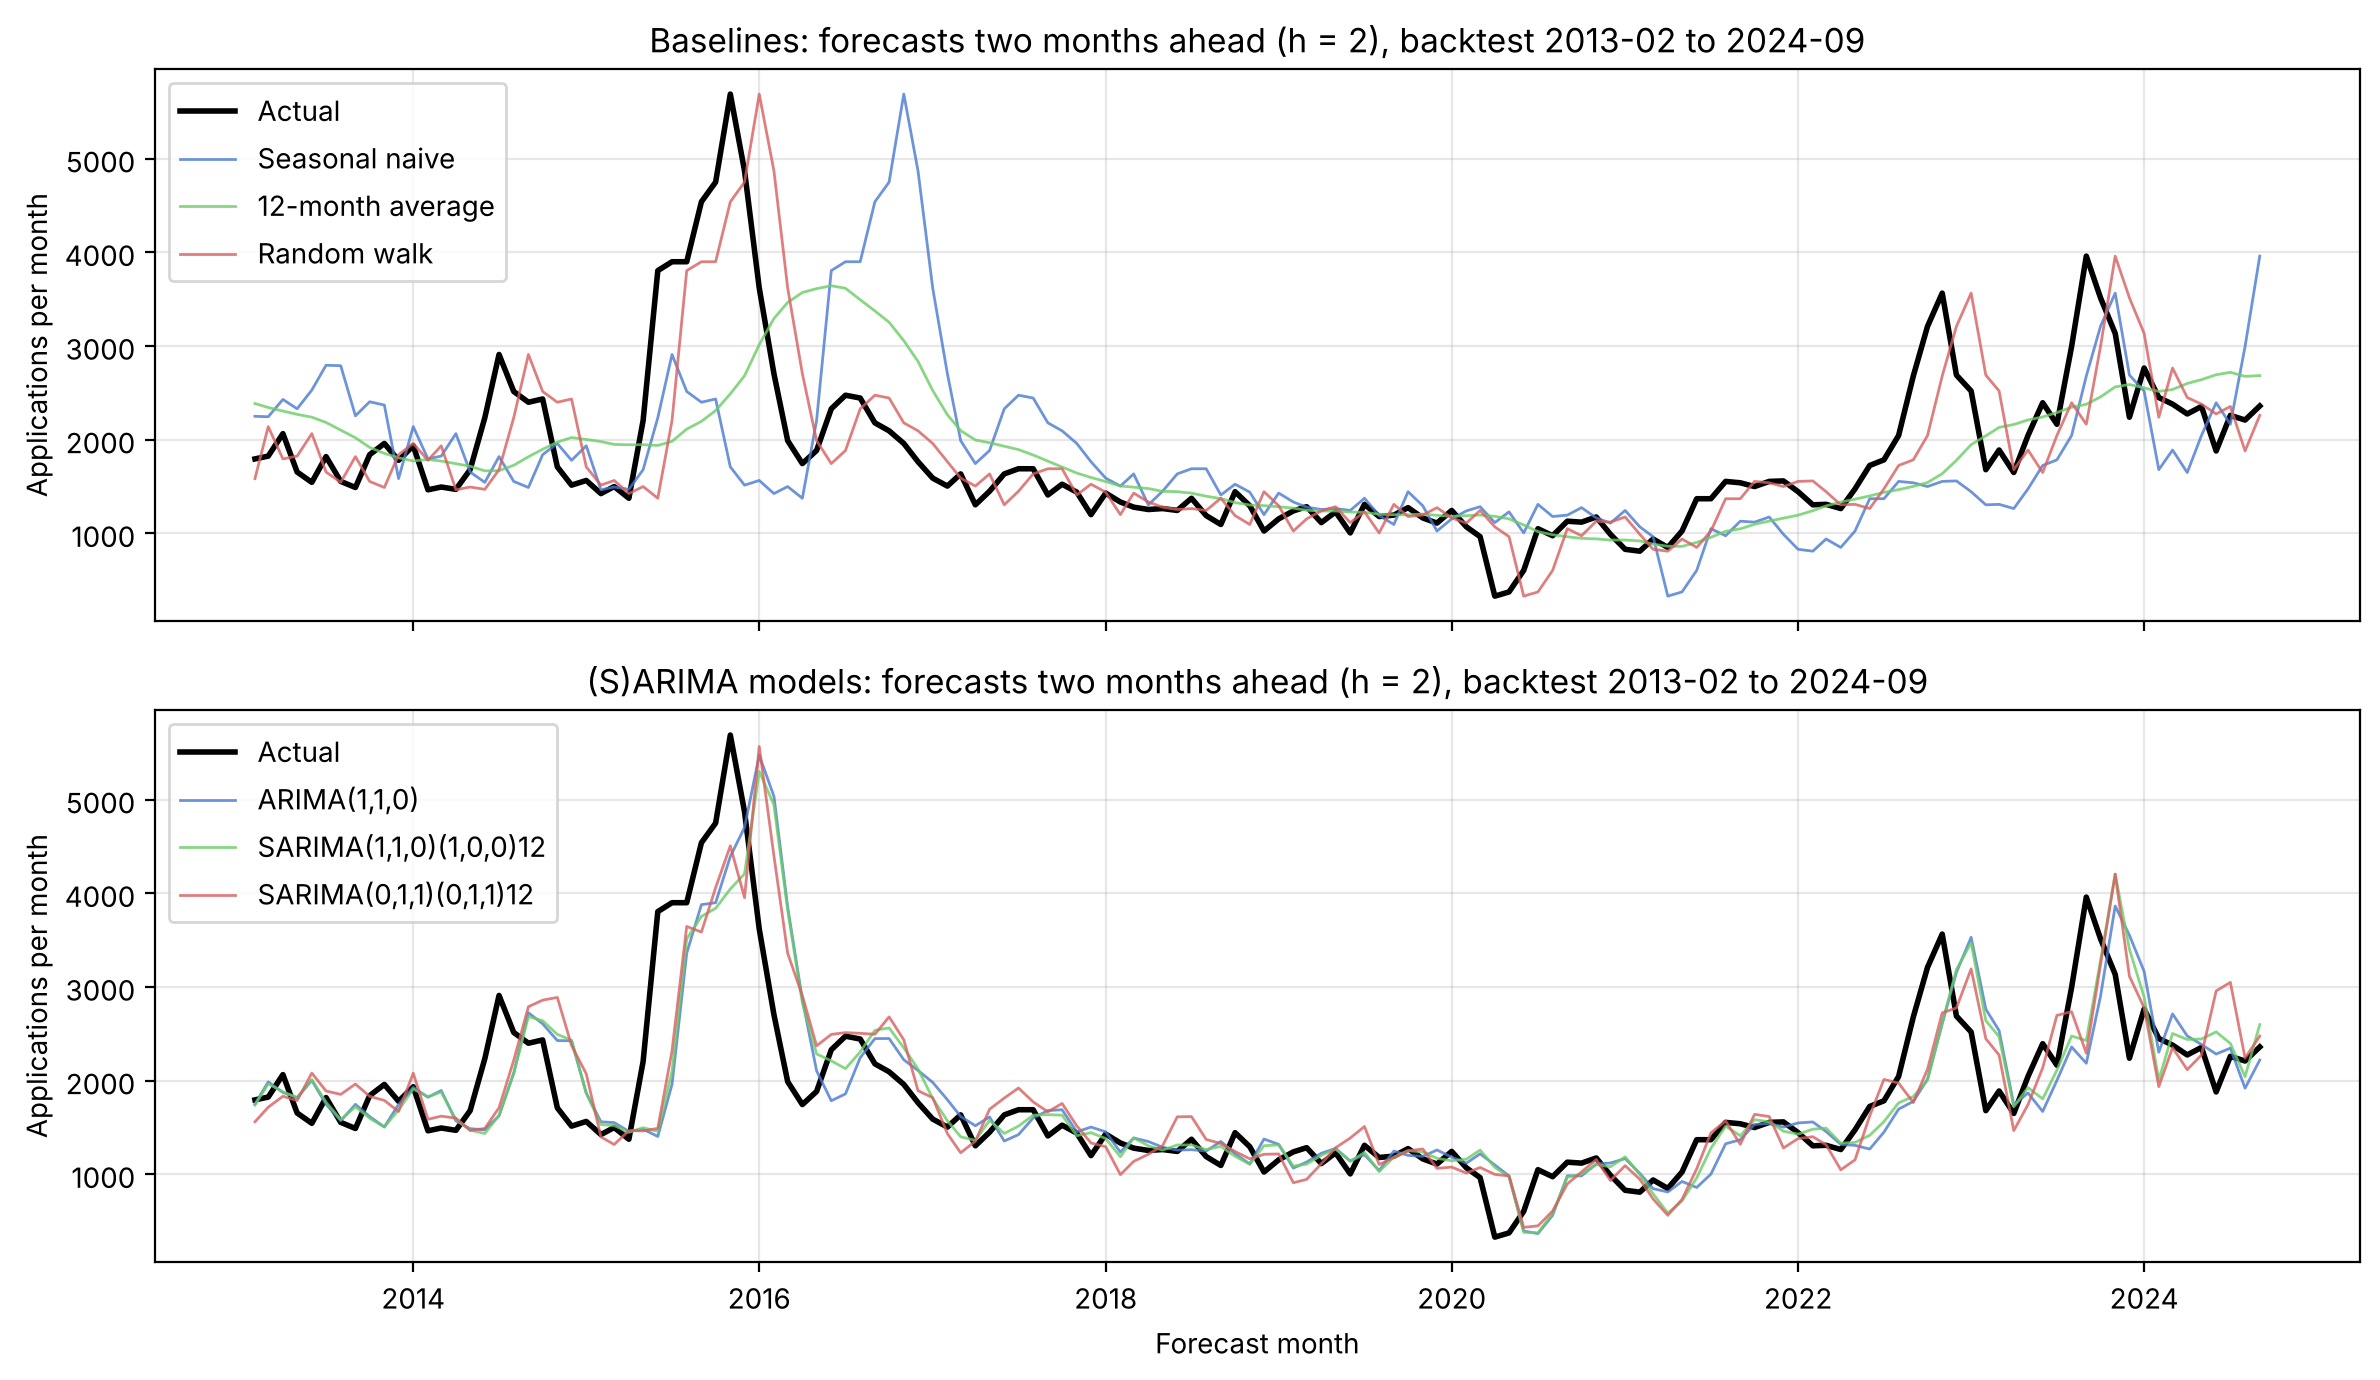

Saved 2520 forecasts with the columns ['model', 'origin', 'month', 'h', 'forecast_log', 'actual_log', 'forecast', 'actual']


In [5]:
%run 02_estimate.ipynb

First origin: 2012-12-01 00:00:00 | last backtest month: 2024-09-01 00:00:00
Table for h = 2: 211 rows (origins) and 14 features
Missing values: 0 | 0


Training rows at the first origin for h = 1: 47


Number of stored forecasts: 1260
Number of forecasts per model and horizon:
model              h
Lasso              1    141
                   2    140
                   3    139
Linear regression  1    141
                   2    140
                   3    139
Ridge              1    141
                   2    140
                   3    139
dtype: int64
Last forecast month: 2024-09-01 00:00:00
All forecast months in the backtest (before 2024-10): True
All forecast months after their origin: True
Missing or infinite forecasts: 0
Ridge: how often each alpha was chosen (grid from 0.1 to 10000)
alpha
0.1         94
1.0          8
10.0        48
100.0      207
1000.0      59
10000.0      4

Lasso: how often each alpha was chosen (grid from 0.0001 to 0.3)
alpha
0.0001     82
0.0010     21
0.0030     21
0.0100    106
0.0300    109
0.1000     54
0.3000     27

Origin: 2024-08-01 00:00:00 | horizon h = 2 | training rows: 186


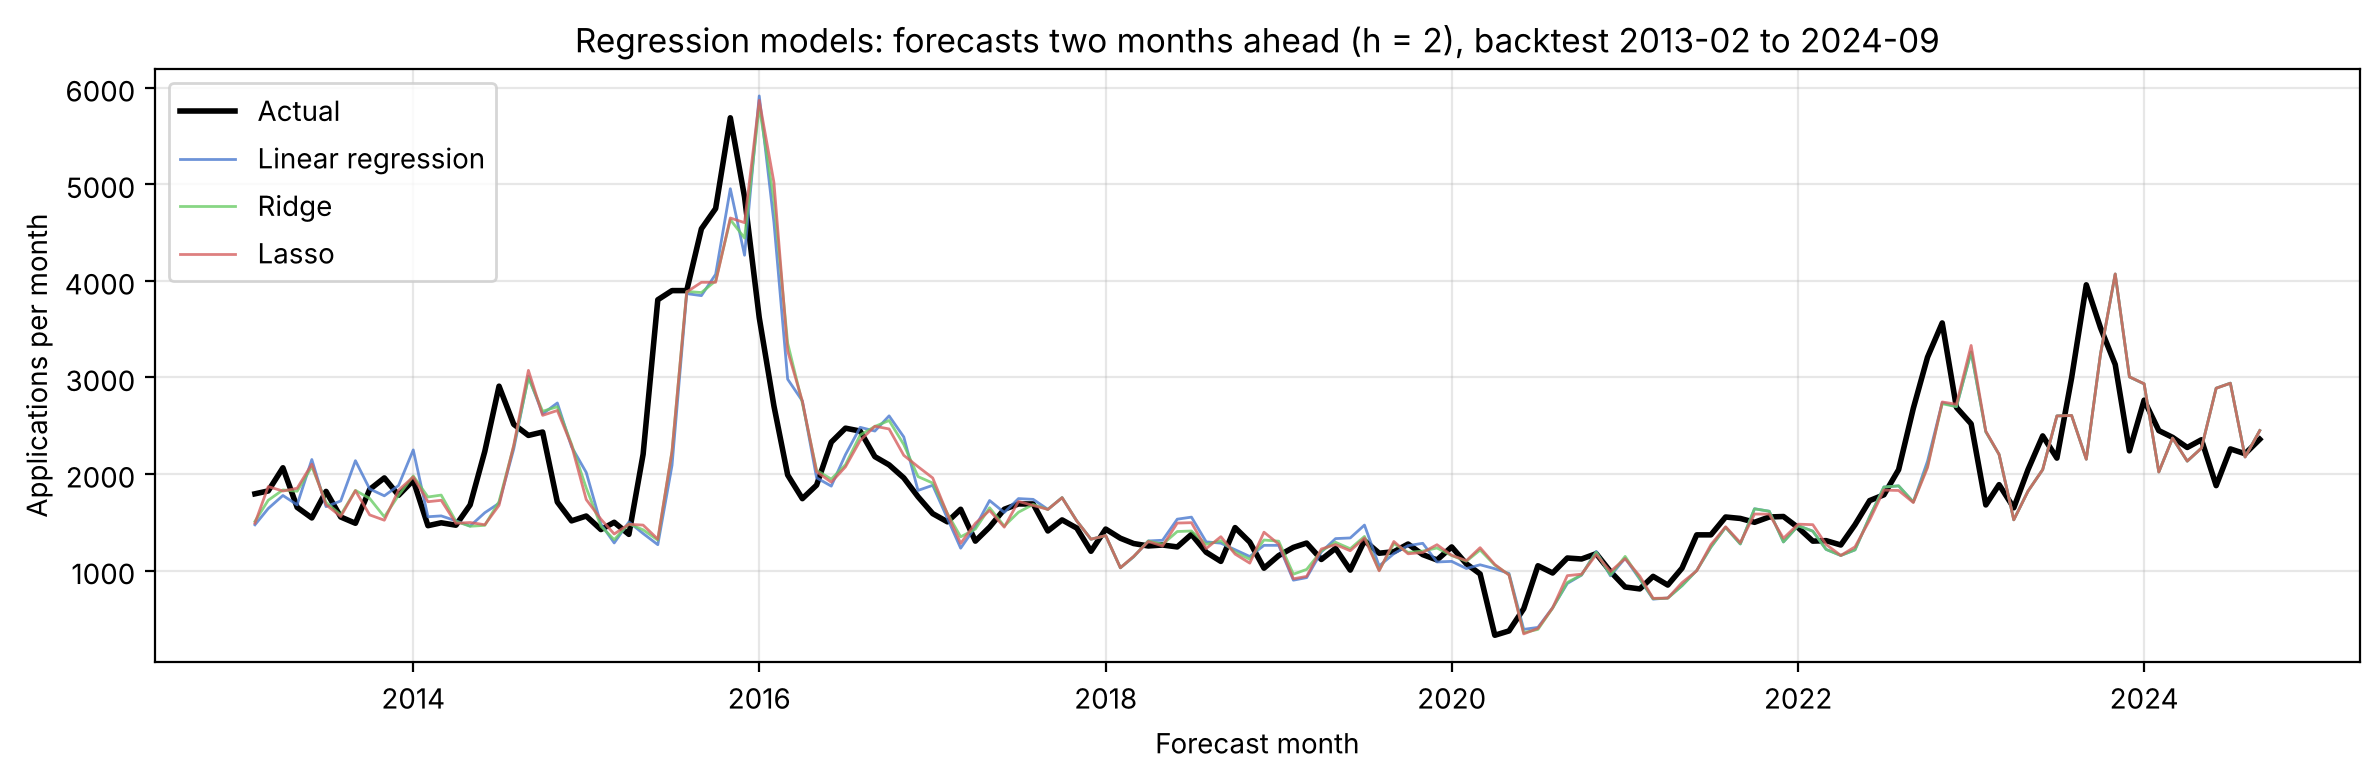

Saved 1260 forecasts with the columns ['model', 'origin', 'month', 'h', 'forecast_log', 'actual_log', 'forecast', 'actual', 'alpha']


In [6]:
%run 02b_estimate_regression.ipynb

In [7]:
%run 02c_estimate_indicator.ipynb

Indicator missing for 12 months (before 2009-01-01 00:00:00 )
Table for h = 2: 207 rows and 16 features
First row: origin 2009-05-01 00:00:00 | missing values: 0


Number of stored forecasts: 1260
model                       h
Lasso + routes              1    141
                            2    140
                            3    139
Linear regression + routes  1    141
                            2    140
                            3    139
Ridge + routes              1    141
                            2    140
                            3    139
dtype: int64

All forecast months in the backtest (before 2024-10): True
All forecast months after their origin: True
Missing or infinite forecasts: 0
Ridge + routes: how often each alpha was chosen (grid from 0.1 to 10000)
alpha
0.1         92
1.0          9
10.0        50
100.0      196
1000.0      65
10000.0      8

Lasso + routes: how often each alpha was chosen (grid from 0.0001 to 0.3)
alpha
0.0001    100
0.0010     11
0.0030     22
0.0100     93
0.0300     78
0.1000     66
0.3000     50

Origin: 2024-08-01 00:00:00 | horizon h = 2 | training rows: 182
Saved 1260 forecasts with the columns [

Forecasts: 5040 | models: 12 | forecast months from 2013-01-01 00:00:00 to 2024-09-01 00:00:00
Best simple baseline at h=2: 12-month average            MAE 527.7 persons   RMSE (log) 0.342
Best (S)ARIMA model at h=2:  SARIMA(0,1,1)(0,1,1)12      MAE 369.0 persons   RMSE (log) 0.274
Best regression model at h=2: Ridge                       MAE 357.9 persons   RMSE (log) 0.279
Best model with routes at h=2: Ridge + routes              MAE 364.1 persons   RMSE (log) 0.281
Best model overall at h=2:   Ridge                       MAE 357.9 persons   RMSE (log) 0.279

Improvement of the best model over the best baseline: 32% lower MAE, 18% lower RMSE (log)
For comparison, average actual number of applications in these months: 1850
Ridge has a lower MAE than 12-month average in 8 of 12 years.
   Spread across years (standard deviation of the yearly MAE): 12-month average 417, Ridge 220
   Gap between the two averages: 167
Ridge has a lower MAE than SARIMA(0,1,1)(0,1,1)12 in 9 of 12 years.
   

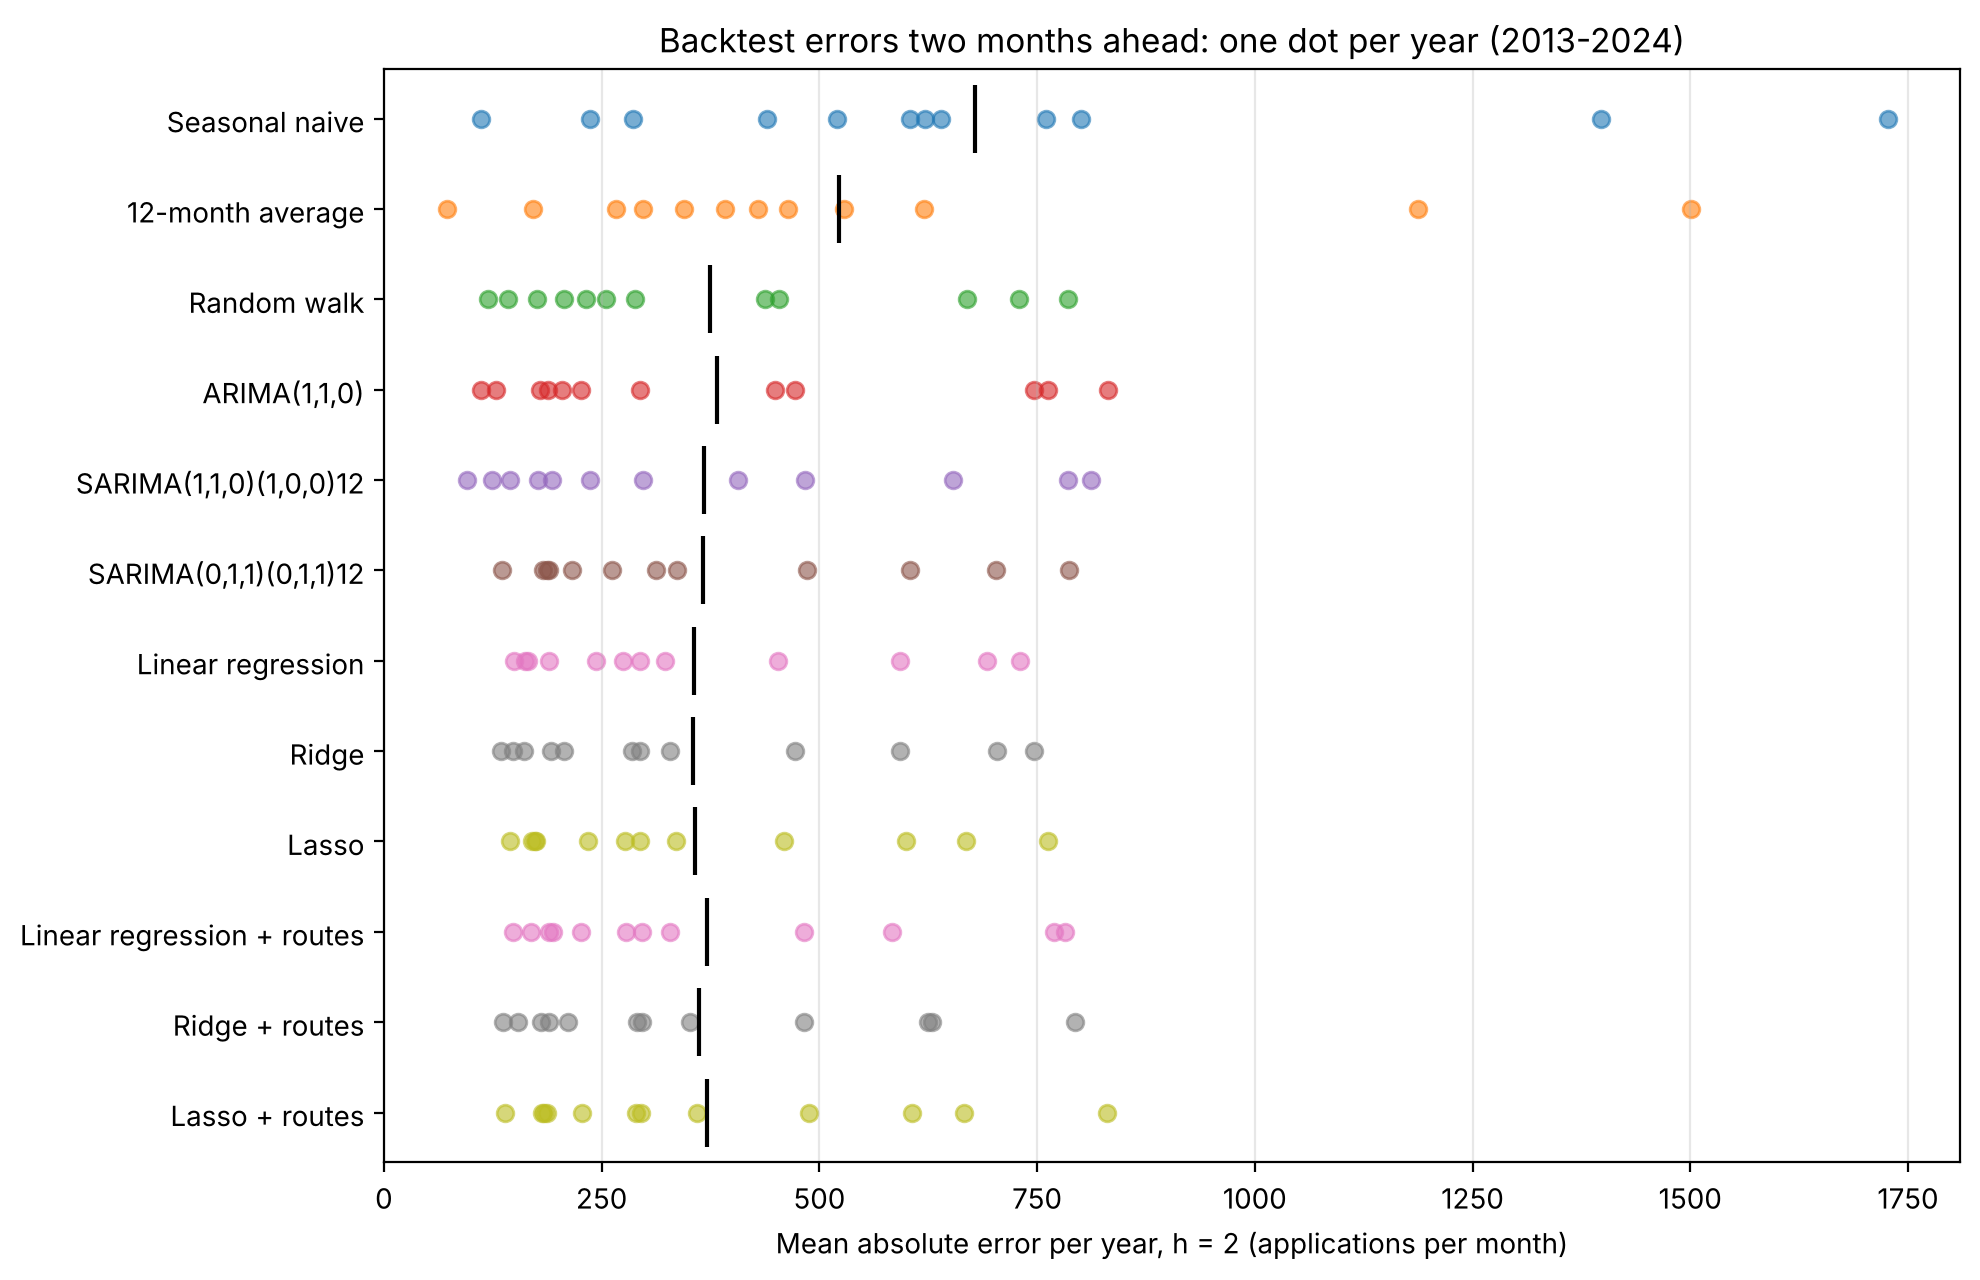

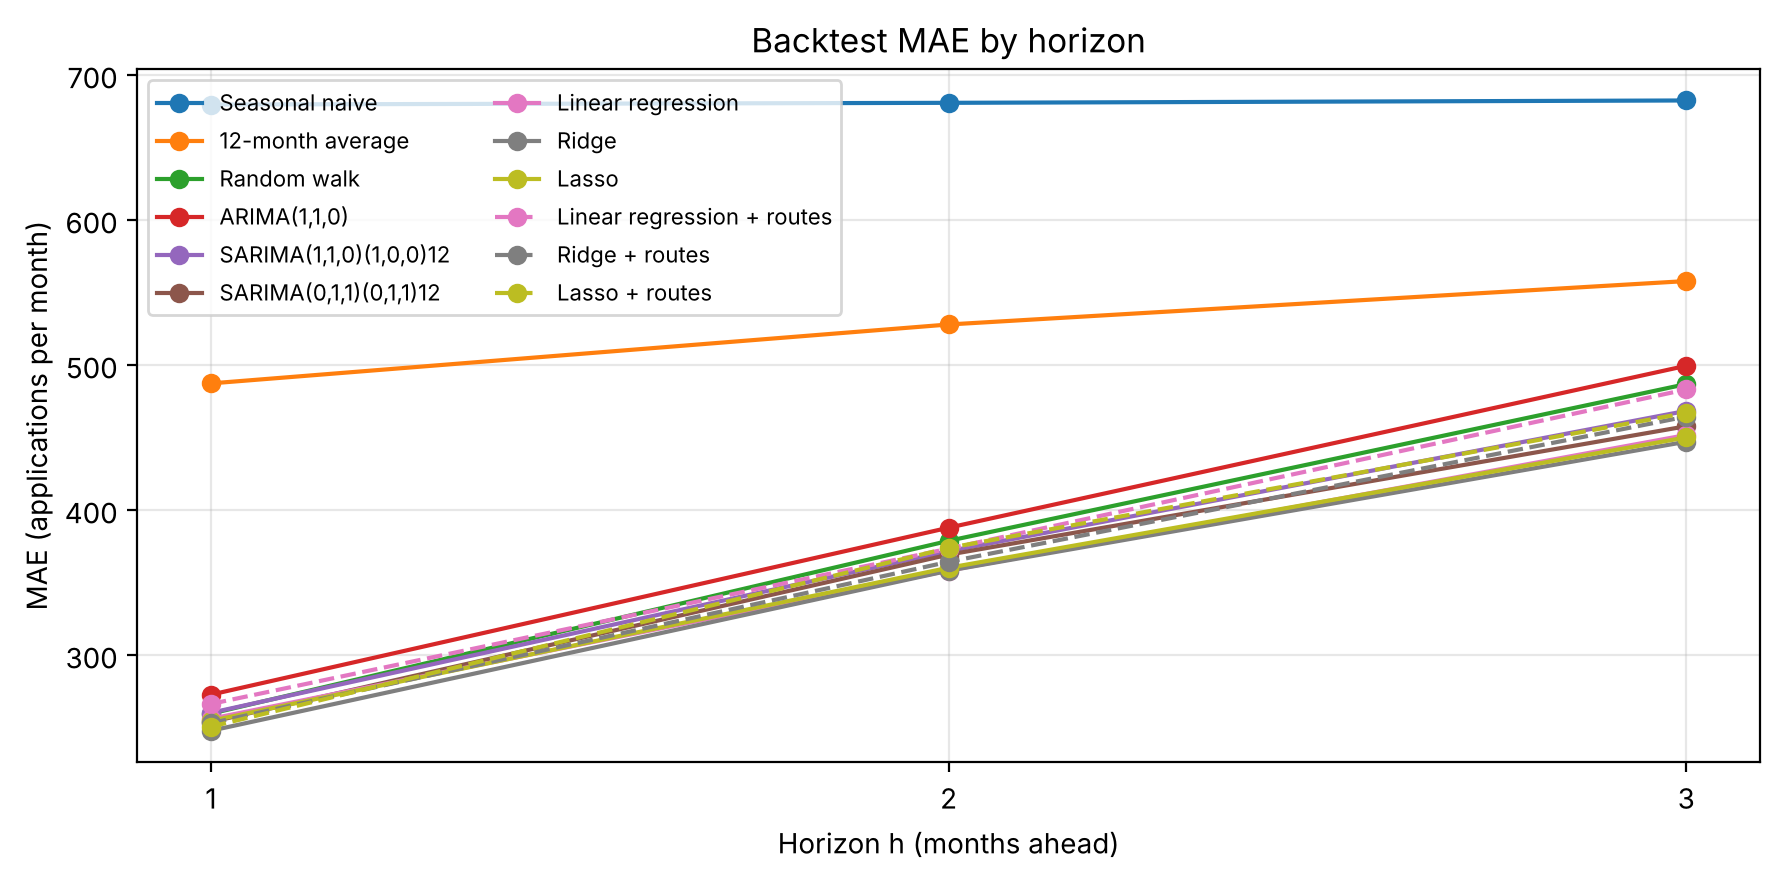

Linear regression + routes  lower MAE than Linear regression  in  3 of 12 years | gap of the averages  -14.8 | spread across years 210
Ridge + routes              lower MAE than Ridge              in  2 of 12 years | gap of the averages   -6.2 | spread across years 220
Lasso + routes              lower MAE than Lasso              in  3 of 12 years | gap of the averages  -13.3 | spread across years 214

   MAE random walk  MAE linear regression  change in MAE (%)  \
h                                                              
1          259.397                255.864             -1.362   
2          378.536                358.007             -5.423   
3          486.619                451.512             -7.214   

   RMSE (log) random walk  RMSE (log) linear regression  
h                                                        
1                   0.195                         0.197  
2                   0.288                         0.278  
3                   0.358                

In [8]:
%run 03_evaluate.ipynb

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Last backtest month: 2024-09-01 00:00:00 | last month: 2026-09-01 00:00:00


model              h
12-month average   1    24
                   2    23
                   3    22
Linear regression  1    24
                   2    23
                   3    22
Random walk        1    24
                   2    23
                   3    22
dtype: int64

All forecast months in the test period: True
All forecast months after their origin: True
Missing or infinite forecasts: 0
Test MAE at h=2: linear regression 188.0 persons, 12-month average 331.3 persons
Improvement: 43% lower MAE, 41% lower RMSE (log)
Success rule of our plan (at least 10% lower MAE than the best simple baseline): True
For comparison, average actual number of applications in these months: 1982

For information (added on 23 November): random walk 269.1 persons; linear regression 30% lower MAE, 30% lower RMSE (log)
                   backtest MAE h=1  test MAE h=1  backtest MAE h=2  \
Linear regression             256.0         149.0             358.0   
12-month average              487.0        

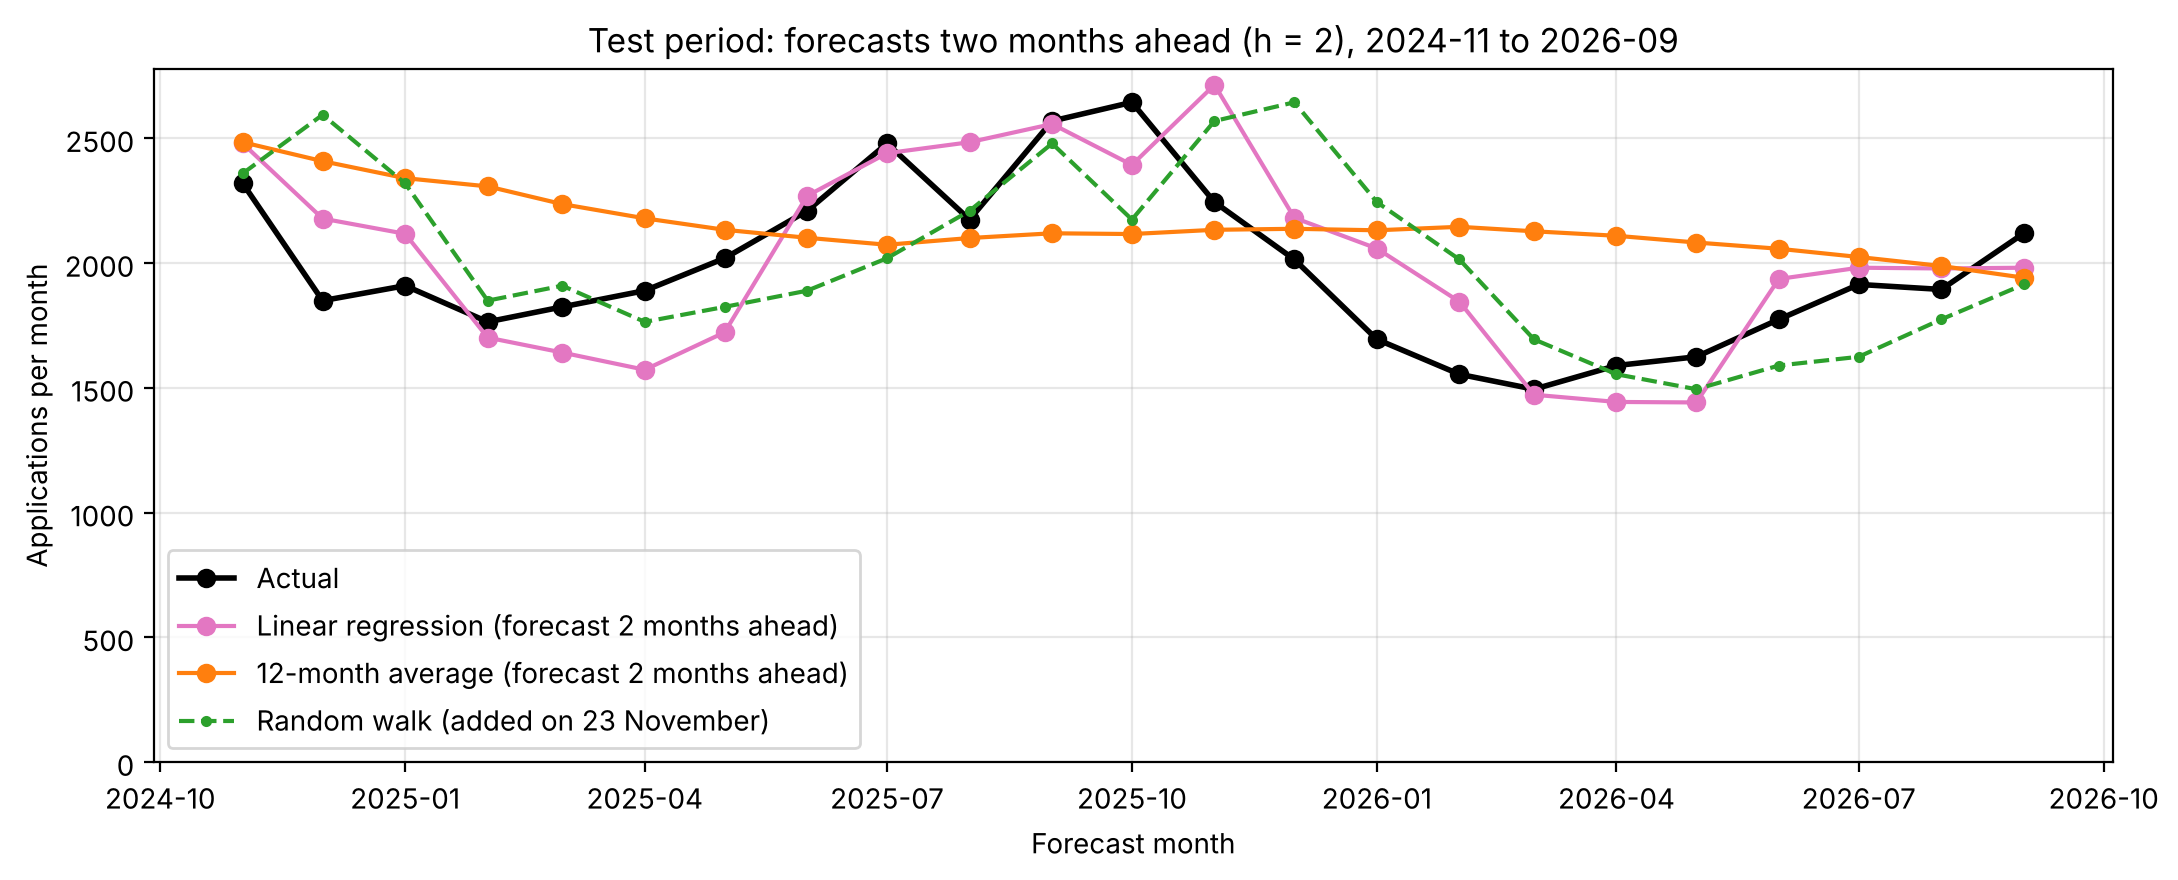

Saved 207 test forecasts


In [9]:
%run 04_test.ipynb

First month with a range: 2015-01 | ranges: 414


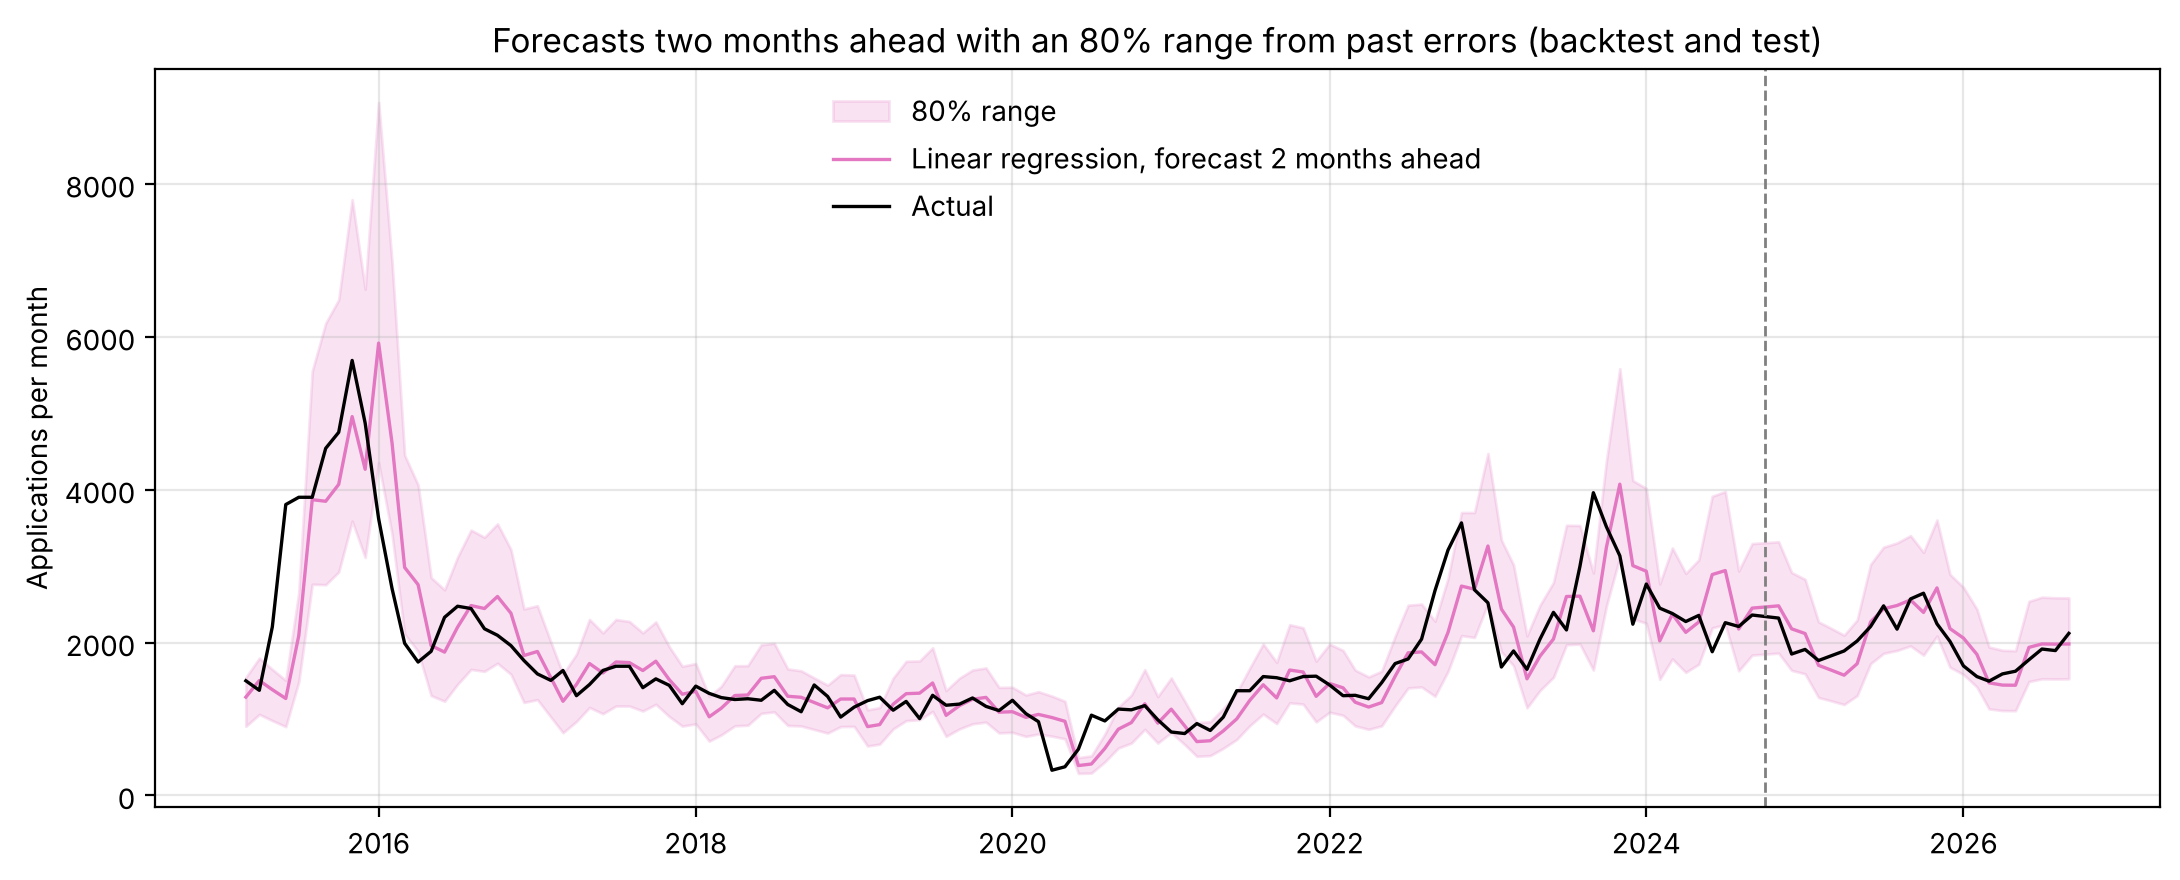

Origin: 2026-09 (last known month)


In [10]:
%run 05_ranges_and_forecast.ipynb